# Les députés représentent-ils bien leurs circonscriptions ?

*Introduction : à rédiger...*

**Problématique.** Nous comparons le profil de chaque député (âge, genre, profession, groupe politique) à celui de sa circonscription (indicateurs INSEE, résultats électoraux), pour mesurer dans quelle mesure l'Assemblée ressemble aux territoires qu'elle représente.

# 1. Données
## 1.1 Sources

| Source | Contenu | Accès |
|---|---|---|
| INSEE, indicateurs par circonscription législative (2022) | 124 indicateurs socio-économiques | Fichier Excel téléchargé |
| INSEE, composition des circonscriptions | Correspondance communes - circonscriptions | Fichier Excel téléchargé |
| Députés actifs de l'Assemblée nationale | Âge, genre, groupe, scores parlementaires | API data.gouv.fr |

Les fichiers bruts sont « gelés » dans `data/data_brut` pour que le projet reste rejouable si les sites changent.

In [1]:
from extraction_donnees import charger_donnees
from jointures import joindre_deputes_insee
from descriptif import (
    preparer_deputes, tableau_groupes, valeurs_manquantes,
    graphique_deputes, graphique_insee,
)

deputes, insee_indic, insee_compo, dico_insee = charger_donnees()
deputes = preparer_deputes(deputes)

print("Députés :", deputes.shape)
print("Indicateurs INSEE :", insee_indic.shape)
print("Composition communes-circonscriptions :", insee_compo.shape)

Députés : (574, 29)
Indicateurs INSEE : (567, 125)
Composition communes-circonscriptions : (35150, 8)


## 1.2 Nettoyage

Les données brutes n'étaient pas exploitables telles quelles :

- **Fichier INSEE des indicateurs** : les données sont dans le premier onglet, précédées de 7 lignes de métadonnées. La fonction `lire_excel_insee` prend donc l'onglet et la ligne d'en-tête en paramètres.
- **Clé de jointure `code_circo`** : l'INSEE utilise 5 caractères (`75018`), la base des députés les départements sur 3 chiffres et les circonscriptions sur 2. Nous avons harmonisé les deux au format INSEE.
- **Corse** : `2a001` côté députés, `2A001` côté INSEE, d'où un passage en majuscules.
- **Saint-Barthélemy** : l'INSEE la regroupe avec Saint-Martin (`97801`), le code `97701` a été rattaché à celle-ci.
- **Valeurs `s` et `nd`** de l'INSEE (secret statistique, non déterminé) : converties en valeurs manquantes.

In [2]:
df = joindre_deputes_insee(deputes, insee_indic)

print("Forme de la table jointe :", df.shape)
print(df["indicateur_present"].value_counts())
print(sorted(df.loc[~df["indicateur_present"], "code_circo"]))

Forme de la table jointe : (574, 154)
indicateur_present
True     563
False     11
Name: count, dtype: int64
['99001', '99002', '99003', '99004', '99005', '99006', '99007', '99008', '99009', '99010', '99011']


## 1.3 Jointure

La jointure est faite à gauche sur `code_circo` : sur 574 députés, **563 ont les indicateurs INSEE de leur circonscription**. Les 11 restants sont les circonscriptions des Français de l'étranger (`99001` à `99011`), pour lesquelles l'INSEE ne publie pas d'indicateurs. Nous les conservons avec des valeurs manquantes, car ils restent utiles pour les statistiques sur les députés eux-mêmes.

## 1.4 Description des données

### Les députés

,effectif,age_moyen,part_femmes
groupeAbrev,,,
RN,121,50.2,32.2
EPR,90,53.1,50.0
LFI-NFP,70,44.3,42.9
SOC,68,56.2,41.2
DR,46,54.5,30.4
ECOS,38,49.8,47.4
DEM,37,57.7,40.5
HOR,35,55.8,34.3
LIOT,24,59.4,25.0


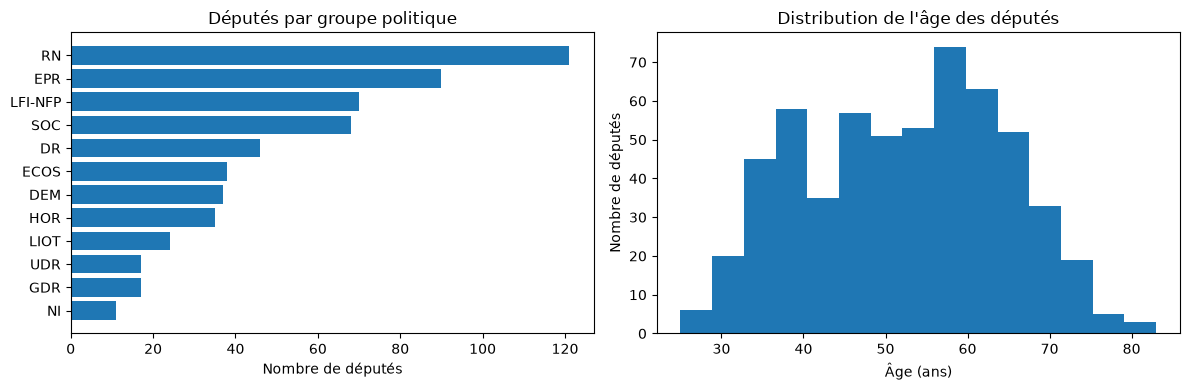

In [3]:
display(tableau_groupes(deputes))
graphique_deputes(deputes);

L'Assemblée compte 574 députés actifs répartis en 12 groupes, dont 38 % de femmes (220). Le RN (121 députés) et EPR (90) sont les groupes les plus nombreux. Trois groupes (GDR, UDR, NI) comptent moins de 20 députés : toute moyenne calculée sur eux sera peu fiable.

L'âge moyen des députés est d'environ 52 ans, mais il varie fortement selon les groupes : de 44 ans pour LFI-NFP et l'UDR à 59 ans pour LIOT. La parité varie aussi beaucoup, de 50 % de femmes chez EPR à 18 % à l'UDR. Ces écarts entre groupes justifient de ne pas traiter les députés comme un ensemble homogène dans la suite.

In [4]:
display(valeurs_manquantes(deputes))

,nb,pct
website,363,63.2
facebook,257,44.8
twitter,218,38.0
scoreParticipationSpecialite,4,0.7
scoreLoyaute,1,0.2
scoreMajorite,1,0.2


Les valeurs manquantes de la base des députés concernent surtout les réseaux sociaux et le site web (38 % à 63 %), variables que nous n'utiliserons pas. Les scores parlementaires sont quasi complets (1 à 4 valeurs manquantes sur 574).

### Les indicateurs INSEE

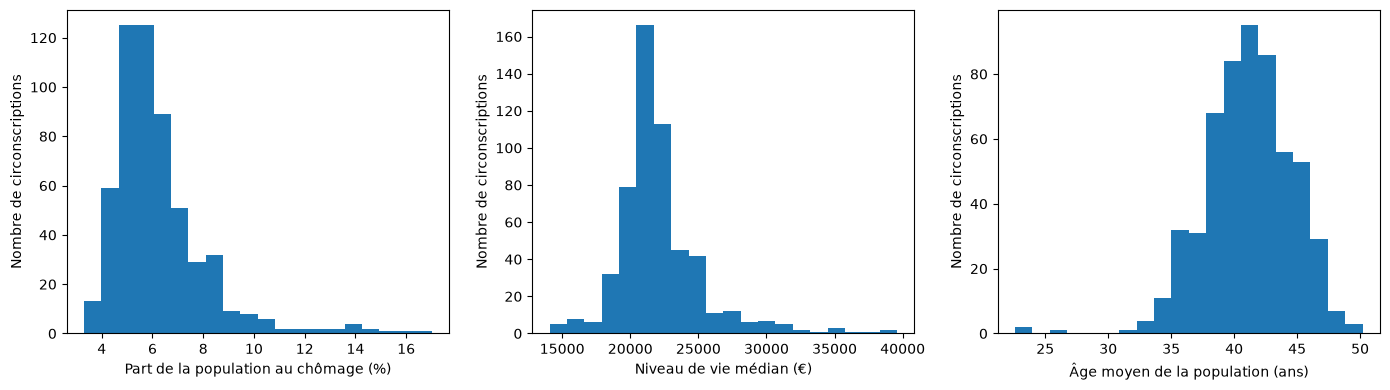

In [5]:
graphique_insee(df);

Les circonscriptions diffèrent nettement : le niveau de vie médian va de 14 070 € à 39 590 € (médiane 21 590 €), et la part de chômage de 3,3 % à 17 %, avec quelques circonscriptions très atypiques. L'âge moyen de la population, autour de 41 ans, est bien inférieur à celui des députés, mais les deux ne sont pas strictement comparables (l'âge INSEE inclut les enfants). Le niveau de vie médian est manquant pour 16 circonscriptions appariées, vraisemblablement à cause du secret statistique.